## DM2 : Boosting et carte de saillance

### 1. Utilisation d'un algorithme de boosting sur de la reconnaissance de chiffres manuscrits

**Initisalisation et train de XGBoost**
#### 1. Toutes classes

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from Boosting import AdaBoost_maison
from sklearn.datasets import fetch_openml
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.utils import resample
from xgboost import DMatrix, XGBClassifier

# Load MNIST data
X_mnist, y_mnist = fetch_openml('mnist_784', return_X_y=True, as_frame=False)
y_mnist = y_mnist.astype(np.int8)  # Convert labels to integers

X_train, y_train, X_test, y_test = train_test_split(X_mnist, y_mnist, random_state=42)
X_train, X_test = X_train/255., X_test/255.

mod_xgb = XGBClassifier(n_estimators=100, max_depth=2, learning_rate=0.1, objective='multi:softmax', num_class=10)

X_train, X_test, y_train, y_test = train_test_split(X_mnist, y_mnist, test_size=0.2, random_state=42)

X_train, X_test = X_train / 255., X_test / 255.

mod_xgb.fit(X_train, y_train)
yhat = mod_xgb.predict_proba(X_test)

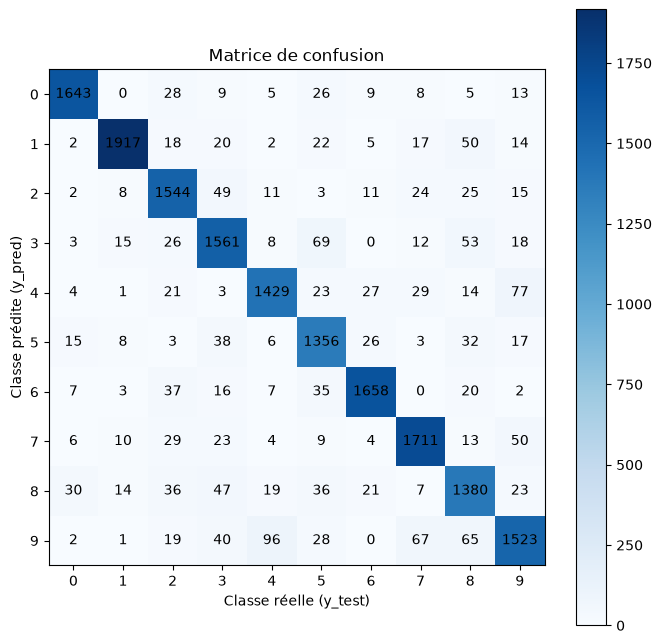

In [4]:
y_pred = yhat.argmax(axis=1)

confusion = np.zeros((10, 10), dtype=int)
np.add.at(confusion, (y_pred, y_test), 1)

plt.figure(figsize=(8, 8))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), range(10))
plt.yticks(range(10), range(10))
plt.xlabel("Classe réelle (y_test)")
plt.ylabel("Classe prédite (y_pred)")
plt.title("Matrice de confusion - Toutes classes")

for i in range(10):
    for j in range(10):
        plt.text(j, i, confusion[i, j], ha="center", va="center")

plt.show()

#### 2. 3 vs 8

In [7]:
c3vs8_idx = np.where((y_mnist == 3) | (y_mnist == 8))[0]
X_c3vs8 = X_mnist[c3vs8_idx]
y_c3vs8 = y_mnist[c3vs8_idx]
y_c3vs8 = np.where(y_c3vs8 == 3, 0, 1)  # Convert labels to binary (0 for 3, 1 for 8)

X1_train, X1_test, y1_train, y1_test = train_test_split(X_c3vs8, y_c3vs8, test_size=0.2, random_state=42)

mod = XGBClassifier(n_estimators=100, max_depth=2, learning_rate=0.1, objective='binary:logistic')
mod.fit(X_c3vs8, y_c3vs8)
yhat_2 = mod.predict(X1_test)

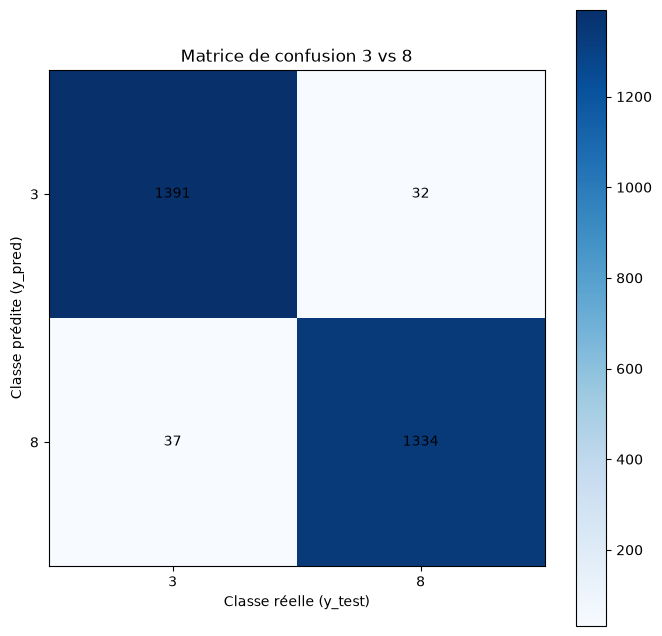

In [8]:
n = len(np.unique(yhat_2))

labels = [3, 8]  # Labels for the classes

confusion = np.zeros((n,n), dtype=int)

np.add.at(confusion, (yhat_2, y1_test), 1)

plt.figure(figsize=(8, 8))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()

plt.xticks(range(n), labels)
plt.yticks(range(n), labels)

plt.xlabel("Classe réelle (y_test)")
plt.ylabel("Classe prédite (y_pred)")
plt.title("Matrice de confusion 3 vs 8")

for i in range(n):
    for j in range(n):
        plt.text(j, i, confusion[i, j], ha="center", va="center")

plt.show()

#### 3.selection hyperparamètres

In [17]:
from tqdm.auto import tqdm

X_bis, y_bis = resample(X_mnist, y_mnist, n_samples=1000, random_state=42, stratify=y_mnist)
X_train, X_test, y_train, y_test = train_test_split(X_bis, y_bis, test_size=0.2, random_state=42, stratify=y_bis)
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

N_ESTI = [20, 50, 150, 180, 210]
DEPTH = [1, 3, 5, 7, 9]
LR = [0.01, 0.1, 0.5, 1]

R = np.zeros((len(N_ESTI), len(DEPTH), len(LR)))
total = len(N_ESTI) * len(DEPTH) * len(LR)

with tqdm(total=total, desc="Grid search XGBoost", unit="config") as pbar:
    for a, n_esti in enumerate(N_ESTI):
        for b, depth in enumerate(DEPTH):
            for c, lr in enumerate(LR):
                mod = XGBClassifier(n_estimators=n_esti, max_depth=depth, learning_rate=lr,
                                    objective='multi:softmax', num_class=10)
                r = cross_validate(mod, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
                R[a, b, c] = r['test_score'].mean()
                pbar.set_postfix(n_est=n_esti, depth=depth, lr=lr, acc=f"{R[a, b, c]:.3f}")
                pbar.update(1)  # affiche temps écoulé, temps restant (ETA) et it/s

Grid search XGBoost:   0%|          | 0/100 [00:00<?, ?config/s]

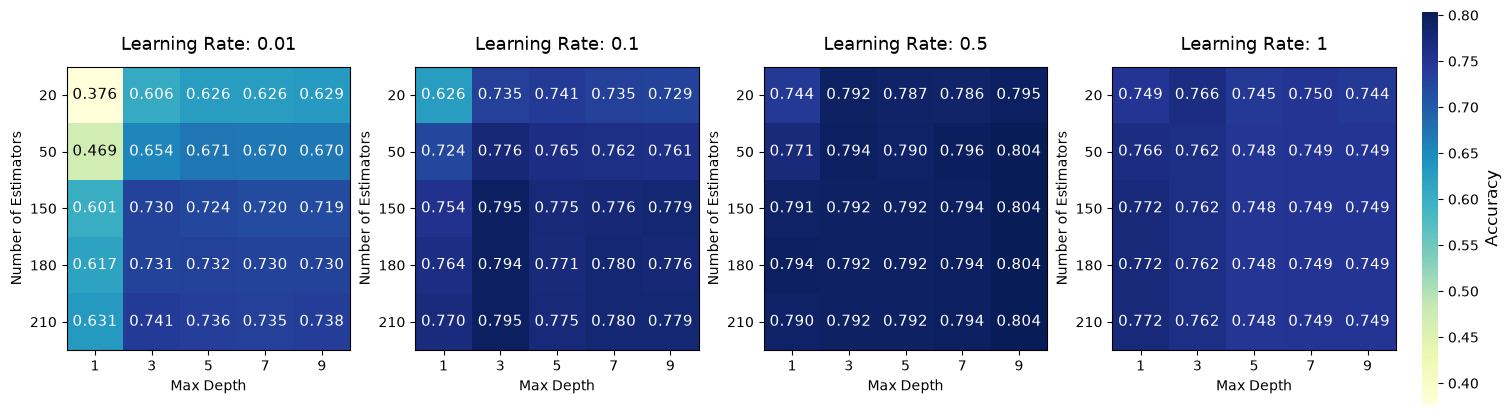

In [18]:
fig, ax = plt.subplots(1, len(LR), figsize=(15, 5), constrained_layout=True)
vmin, vmax = R.min(), R.max()

for i, lr in enumerate(LR):
    im = ax[i].imshow(R[:, :, i], cmap='YlGnBu', vmin=vmin, vmax=vmax)
    ax[i].set_title(f'Learning Rate: {lr}', fontsize=13, pad=12)
    ax[i].set_xticks(range(len(DEPTH)), DEPTH)
    ax[i].set_yticks(range(len(N_ESTI)), N_ESTI)
    ax[i].set_xlabel('Max Depth')
    ax[i].set_ylabel('Number of Estimators')

    for j in range(len(N_ESTI)):
        for k in range(len(DEPTH)):
            value = R[j, k, i]
            ax[i].text(k, j, f'{value:.3f}', ha='center', va='center', fontsize=11,
                       color='white' if value > (vmin + vmax) / 2 else 'black')

cbar = fig.colorbar(im, ax=ax, shrink=0.8, aspect=25, pad=0.02)
cbar.set_label('Accuracy', fontsize=12)
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=10)

  0%|          | 0/10 [00:00<?, ?it/s]

Meilleure accuracy CV : 0.88375
Meilleurs paramètres  : {'n_estimators': 199, 'max_depth': 6, 'learning_rate': 0.395823401673732}


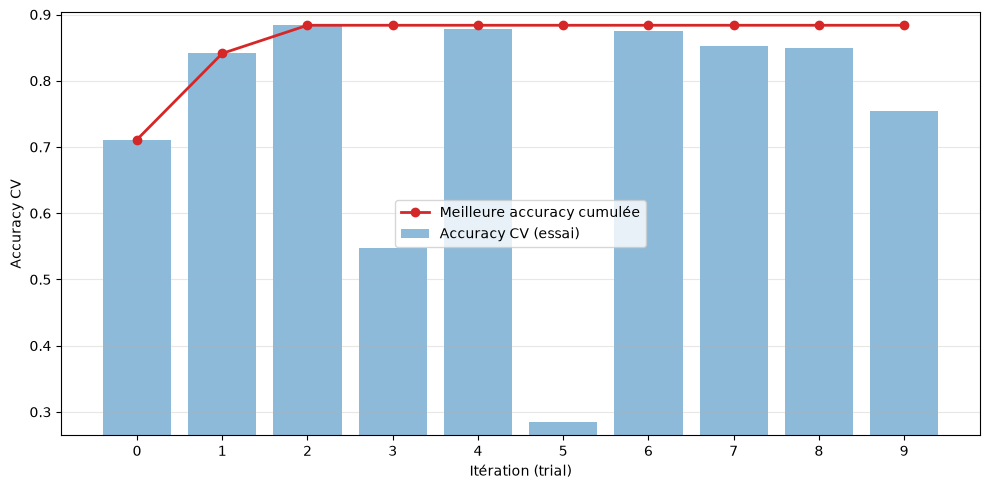

In [14]:
import optuna

N_TRIAL = 10

X_bis, y_bis = resample(X_mnist, y_mnist, n_samples=1000)
X_train, X_test, y_train, y_test = train_test_split(X_bis, y_bis, test_size=0.2, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True)

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 20, 300),
        'max_depth': trial.suggest_int('max_depth', 1, 8),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.5, log=True),
    }
    mod = XGBClassifier(objective='multi:softmax', num_class=10, **params)
    r = cross_validate(mod, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    return r['test_score'].mean()

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=N_TRIAL, show_progress_bar=True)

print("Meilleure accuracy CV :", study.best_value)
print("Meilleurs paramètres  :", study.best_params)

trials = [t for t in study.trials if t.value is not None]
scores = [t.value for t in trials]
best_so_far = np.maximum.accumulate(scores)
iters = np.arange(len(scores))

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(iters, scores, color="tab:blue", alpha=0.5, label="Accuracy CV (essai)")
ax.plot(iters, best_so_far, color="tab:red", marker="o", lw=2, label="Meilleure accuracy cumulée")
ax.set_xlabel("Itération (trial)")
ax.set_ylabel("Accuracy CV")
ax.set_ylim(min(scores) - 0.02, max(scores) + 0.02)
ax.set_xticks(iters)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### 2. Réalisation de cartes de saillance
#### 1. Carte de saillance par classe

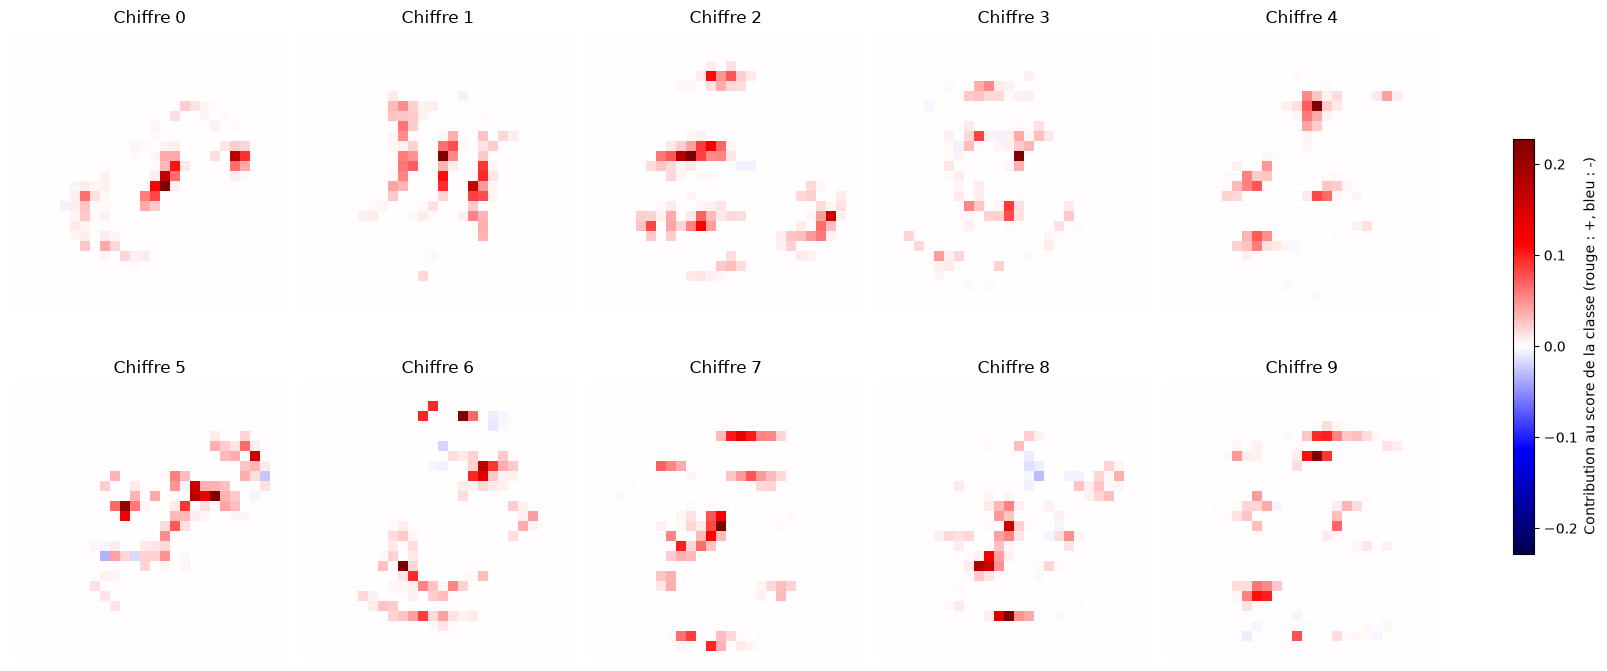

In [19]:
booster = mod_xgb.get_booster()
saliency = np.zeros((10, 28, 28))

for k in range(10):
    X_k = X_test[y_test == k][:500]
    # contribs : (n_echantillons, n_classes, 784 pixels + biais)
    contribs = booster.predict(DMatrix(X_k), pred_contribs=True)
    # contribution moyenne de chaque pixel au score de la classe k, pour les images de classe k
    saliency[k] = contribs[:, k, :-1].mean(axis=0).reshape(28, 28)

fig, axes = plt.subplots(2, 5, figsize=(16, 7), constrained_layout=True)
for k, ax in enumerate(axes.ravel()):
    vmax = np.abs(saliency[k]).max()
    im = ax.imshow(saliency[k], cmap='seismic', vmin=-vmax, vmax=vmax)
    ax.set_title(f'Chiffre {k}')
    ax.axis('off')
fig.colorbar(im, ax=axes, shrink=0.6, label='Contribution au score de la classe (rouge : +, bleu : -)')
plt.show()


### 3. Passage par un enchâssement (embedding)